# Pandas Hands-on Lab: From Tables to Real Analysis

## Student Practice Notebook

**Name:** Sreehari Nukanaboina
**Register Number:** AP24110010676
**Date:** 20/08/2026
## Learning Objectives

After completing this lab, you will be able to:

- Load and inspect a real dataset with pandas
- Select, filter, and sort rows and columns
- Create new columns from existing ones
- Explore categorical data with `value_counts()`
- Clean data: handle duplicates, missing values, wrong dtypes, and column names
- Summarize data with `groupby()`
- Combine two related tables with `merge()`
- Visualize a DataFrame with matplotlib
- Save your results back to a file

### How to use this notebook
This continues directly from last week's NumPy lab — pandas is built on top of NumPy arrays, so everything you already know about arrays applies here, just organized into labeled rows and columns (a **DataFrame**).

- **Demonstration** cells: run and read.
- **Practice** cells: write your own code.
- **Predict-then-run**: write your prediction before running.
- **Reflection**: short written answers in your own words.


## Part 1: Loading and Inspecting Data

We'll use the classic **tips** dataset — real restaurant bill data. Each row is one bill.

### Demonstration


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 10)
pd.set_option('display.precision', 3)

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
tips = pd.read_csv(url)
tips.head()


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


**Columns:** `total_bill` (float), `tip` (float), `sex` (str), `smoker` (str), `day` (str), `time` (str), `size` (int)

A pandas **DataFrame** is a 2D table, similar to a NumPy 2D array, but with labeled columns and an index for each row.


In [3]:
print("Shape:", tips.shape)
print("\nInfo:")
tips.info()


Shape: (244, 7)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


### Student Practice

1. Print `tips.describe()` to see summary statistics.
2. Print the column names using `tips.columns`.
3. Print just the last 5 rows using `tips.tail()`.


In [4]:
print(tips.describe())
print(tips.columns)
print(tips.tail())


       total_bill      tip     size
count     244.000  244.000  244.000
mean       19.786    2.998    2.570
std         8.902    1.384    0.951
min         3.070    1.000    1.000
25%        13.348    2.000    2.000
50%        17.795    2.900    2.000
75%        24.127    3.562    3.000
max        50.810   10.000    6.000
Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')
     total_bill   tip     sex smoker   day    time  size
239       29.03  5.92    Male     No   Sat  Dinner     3
240       27.18  2.00  Female    Yes   Sat  Dinner     2
241       22.67  2.00    Male    Yes   Sat  Dinner     2
242       17.82  1.75    Male     No   Sat  Dinner     2
243       18.78  3.00  Female     No  Thur  Dinner     2


**Reflection:** Compare `tips.shape` (NumPy-style) to `tips.info()`. What extra information does `.info()` give you that `.shape` alone doesn't?

*Your answer:*
because df.shape give only (no of rows , no of columns) where as df.info() also no of rows , no of columns along extra information that describes about features like non-nulls and type of features


## Part 2: Exploring Categorical Data with `value_counts()`

Before filtering or grouping, it helps to know what categories exist in a column and how common each is.

### Demonstration


In [5]:
tips['day'].value_counts()


,count
day,
Sat,87
Sun,76
Thur,62
Fri,19


### Student Practice

1. Use `value_counts()` on the `time` column. Which time period has more bills — Lunch or Dinner?
2. Use `value_counts()` on `smoker`. What percentage of customers were smokers? (Hint: `value_counts(normalize=True)` gives proportions instead of counts.)


In [6]:
time_counts = tips['time'].value_counts()
print(time_counts)
most_frequent_time = time_counts.index[0]
most_frequent_count = time_counts.iloc[0]
print(f"The time period with more bills is {most_frequent_time} with {most_frequent_count} bills.")

smoker_counts= tips['smoker'].value_counts(normalize=True)
print(smoker_counts)
smoker_percentage = smoker_counts.iloc[1] * 100
print(f"the percentage of {smoker_percentage} are customers ")



time
Dinner    176
Lunch      68
Name: count, dtype: int64
The time period with more bills is Dinner with 176 bills.
smoker
No     0.619
Yes    0.381
Name: proportion, dtype: float64
the percentage of 38.114754098360656 are customers 


## Part 3: Selecting and Filtering

### Demonstration


In [7]:
# Select specific columns
tips[['total_bill','tip']].head()


,total_bill,tip
0,16.99,1.01
1,10.34,1.66
2,21.01,3.50
3,23.68,3.31
4,24.59,3.61


In [8]:
# Select rows by position
tips.iloc[0:5]


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [9]:
# Select rows by label/condition using .loc
tips.loc[tips['day']=='Sun', ['total_bill','tip','size']].head()


,total_bill,tip,size
0,16.99,1.01,2
1,10.34,1.66,3
2,21.01,3.50,3
3,23.68,3.31,2
4,24.59,3.61,4


In [10]:
# Boolean filtering (same idea as NumPy boolean indexing!)
big_tables = tips[tips['size'] >= 5]
big_tables.head()


,total_bill,tip,sex,smoker,day,time,size
125,29.80,4.20,Female,No,Thur,Lunch,6
141,34.30,6.70,Male,No,Thur,Lunch,6
142,41.19,5.00,Male,No,Thur,Lunch,5
143,27.05,5.00,Female,No,Thur,Lunch,6
155,29.85,5.14,Female,No,Sun,Dinner,5


**Note the parallel to NumPy:** `tips[tips['size'] >= 5]` uses a boolean condition to filter rows — exactly like `marks[marks > 60]` did with NumPy arrays in last week's lab. The DataFrame version just keeps the whole row instead of a single value.


In [11]:
# Run your filter here and check your prediction

tips[(tips['smoker']=='Yes') & (tips['time']=='Lunch')].shape

(23, 7)

### Student Practice — predict then check

Before running, predict: how many rows will `tips[(tips['smoker']=='Yes') & (tips['time']=='Lunch')]` return? You don't need an exact number — just predict whether it will be a small or large subset of the 244 total rows, and why.

*Your prediction:*
it can be 50 beacuse no of smokers is 93 and no of lunchs in time around 60 based on our previous cell executuions

## Part 4: Sorting

### Demonstration


In [12]:
tips_sorted = tips.sort_values(['total_bill','tip'], ascending=[False, True])
tips_sorted.head()


,total_bill,tip,sex,smoker,day,time,size
170,50.81,10.00,Male,Yes,Sat,Dinner,3
212,48.33,9.00,Male,No,Sat,Dinner,4
59,48.27,6.73,Male,No,Sat,Dinner,4
156,48.17,5.00,Male,No,Sun,Dinner,6
182,45.35,3.50,Male,Yes,Sun,Dinner,3


### Student Practice

Sort `tips` by `tip` in descending order and display the top 5 highest tips. Which day(s) do they mostly occur on?


In [13]:
tips_sortedby_tip = tips.sort_values('tip', ascending=False)
top_5_highest_tips = tips_sortedby_tip.head(5)['day'].value_counts().index[0]
print(top_5_highest_tips)


Sat


## Part 5: Creating New Columns

### Demonstration


In [14]:
tips = tips.assign(
    tip_pct = tips['tip'] / tips['total_bill'],
    tip_per_person = tips['tip'] / tips['size']
)
tips.head()


,total_bill,tip,sex,smoker,day,time,size,tip_pct,tip_per_person
0,16.99,1.01,Female,No,Sun,Dinner,2,0.059,0.505
1,10.34,1.66,Male,No,Sun,Dinner,3,0.161,0.553
2,21.01,3.50,Male,No,Sun,Dinner,3,0.167,1.167
3,23.68,3.31,Male,No,Sun,Dinner,2,0.140,1.655
4,24.59,3.61,Female,No,Sun,Dinner,4,0.147,0.902


### Student Practice

Filter for `day='Sat'` and `size >= 3`, add a new column `bill_per_person = total_bill / size`, then sort descending by that column and show the top 5.


In [15]:
tips[(tips['day'] == 'Sat') & (tips['size'] > 3 )]\
    .assign(bill_per_person = lambda x: x['total_bill'] / x['size']) \
    .sort_values('bill_per_person', ascending = False).head()

,total_bill,tip,sex,smoker,day,time,size,tip_pct,tip_per_person,bill_per_person
212,48.33,9.00,Male,No,Sat,Dinner,4,0.186,2.250,12.082
59,48.27,6.73,Male,No,Sat,Dinner,4,0.139,1.683,12.068
23,39.42,7.58,Male,No,Sat,Dinner,4,0.192,1.895,9.855
207,38.73,3.00,Male,Yes,Sat,Dinner,4,0.077,0.750,9.682
56,38.01,3.00,Male,Yes,Sat,Dinner,4,0.079,0.750,9.502


## Part 6: Cleaning Data

Real data is rarely perfect. We'll cover 4 common cleaning tasks: duplicates, missing values, wrong dtypes, and messy column names.

### 6a. Duplicates


In [16]:
print("Duplicate rows:", tips.duplicated().sum())
tips_clean = tips.drop_duplicates()
print("Shape after dropping duplicates:", tips_clean.shape)


Duplicate rows: 1
Shape after dropping duplicates: (243, 9)


### 6b. Missing Values

Let's deliberately introduce some missing values to practice on, since the original dataset is clean.

In [17]:
tips_messy = tips.copy()
tips_messy.loc[5:8, 'total_bill'] = np.nan
tips_messy.loc[15, 'day'] = np.nan

print("Missing values per column:")
print(tips_messy.isna().sum())


Missing values per column:
total_bill        4
tip               0
sex               0
smoker            0
day               1
time              0
size              0
tip_pct           0
tip_per_person    0
dtype: int64


### Student Practice

1. Drop rows with any missing values using `.dropna()` and check the new shape.
2. Instead of dropping, fill missing `total_bill` values with the column's mean using `.fillna()`. Compare the two approaches — when would you choose one over the other?


In [18]:
tips_messy = tips_messy.dropna()

print("Shape after dropping rows with missing values:", tips_messy.shape)

tips_messy = tips.copy()
tips_messy.loc[5:8, 'total_bill'] = np.nan
tips_messy.loc[15, 'day'] = np.nan

tips_messy['total_bill'] = tips_messy['total_bill'].fillna(tips_messy['total_bill'].mean())
print("Shape after filling missing values:", tips_messy.shape)


Shape after dropping rows with missing values: (239, 9)
Shape after filling missing values: (244, 9)


### 6c. Fixing Data Types

### Demonstration


In [19]:
tips_dtypes = tips.copy()
print("Before:", tips_dtypes['size'].dtype)

tips_dtypes['size'] = tips_dtypes['size'].astype('int32')
tips_dtypes['day'] = tips_dtypes['day'].astype('category')

print("After:", tips_dtypes['size'].dtype, tips_dtypes['day'].dtype)


Before: int64
After: int32 category


### 6d. Renaming Columns

### Demonstration


In [20]:
tips_renamed = tips.rename(columns={'size': 'party_size', 'tip_pct': 'tip_percentage'})
tips_renamed.columns


Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'party_size',
       'tip_percentage', 'tip_per_person'],
      dtype='object')

### Student Practice

Rename `total_bill` to `bill_amount` and `smoker` to `is_smoker` in a copy of `tips`. Print the new column list to confirm.


In [21]:

tips_r = tips.copy()
tips_r = tips_r.rename(columns={'total_bill':'bill_amount','smoker':'is_smoker'})
print(tips_r.columns)

Index(['bill_amount', 'tip', 'sex', 'is_smoker', 'day', 'time', 'size',
       'tip_pct', 'tip_per_person'],
      dtype='object')


## Part 7: Summarizing with `groupby()`

`groupby()` is one of the most powerful pandas tools — it splits data into groups, applies a calculation to each group, then combines the results. This is the tabular equivalent of the `np.mean()` per-category calculations you'd otherwise have to write manually with loops.

### Demonstration


In [22]:
tips.groupby('day')['total_bill'].mean()


,total_bill
day,
Fri,17.152
Sat,20.441
Sun,21.410
Thur,17.683


In [23]:
# Multiple aggregations at once
tips.groupby('day').agg(
    avg_bill=('total_bill','mean'),
    avg_tip=('tip','mean'),
    n_bills=('total_bill','size')
)


,avg_bill,avg_tip,n_bills
day,,,
Fri,17.152,2.735,19
Sat,20.441,2.993,87
Sun,21.410,3.255,76
Thur,17.683,2.771,62


### Student Practice — predict then check

Predict: will average tip percentage (`tip_pct`) be higher at Lunch or Dinner? Write your guess, then check with `groupby('time')['tip_pct'].mean()`.

*Your prediction:*
dinner



In [24]:
# Check your prediction here
tips.groupby('time')['tip_pct'].mean()


,tip_pct
time,
Dinner,0.160
Lunch,0.164


**Reflection:** In your own words, explain what `groupby()` does, using the day/total_bill example above.

*Your answer:*
it split days to groups and calculate avg total_bill in each group

## Part 8: Merging Two Tables

Real-world data often lives in separate tables that need to be joined — e.g. a customer table and an orders table. Let's create a small second table and merge it with `tips`.

### Demonstration


In [25]:
# A lookup table: average tip percentage benchmark per day (made up for practice)
day_benchmark = pd.DataFrame({
    'day': ['Thur','Fri','Sat','Sun'],
    'benchmark_tip_pct': [0.15, 0.16, 0.18, 0.17]
})

merged = tips.merge(day_benchmark, on='day', how='left')
merged[['day','tip_pct','benchmark_tip_pct']].head()


,day,tip_pct,benchmark_tip_pct
0,Sun,0.059,0.17
1,Sun,0.161,0.17
2,Sun,0.167,0.17
3,Sun,0.140,0.17
4,Sun,0.147,0.17


### Student Practice

Create your own small DataFrame called `time_rating` with two columns: `time` (`Lunch`, `Dinner`) and `popularity_score` (any numbers you choose, e.g. 7 and 9). Merge it with `tips` on the `time` column and display the first 5 rows of the result.


In [26]:
# Write your answer here

time_rating = pd.DataFrame({
    'time': ['Lunch', 'Dinner'],
    'popularity_score': [7, 9]
})
merged = tips.merge(time_rating, on='time', how='left')
merged.head()


,total_bill,tip,sex,smoker,day,time,size,tip_pct,tip_per_person,popularity_score
0,16.99,1.01,Female,No,Sun,Dinner,2,0.059,0.505,9
1,10.34,1.66,Male,No,Sun,Dinner,3,0.161,0.553,9
2,21.01,3.50,Male,No,Sun,Dinner,3,0.167,1.167,9
3,23.68,3.31,Male,No,Sun,Dinner,2,0.140,1.655,9
4,24.59,3.61,Female,No,Sun,Dinner,4,0.147,0.902,9


## Part 9: Visualization

### Demonstration


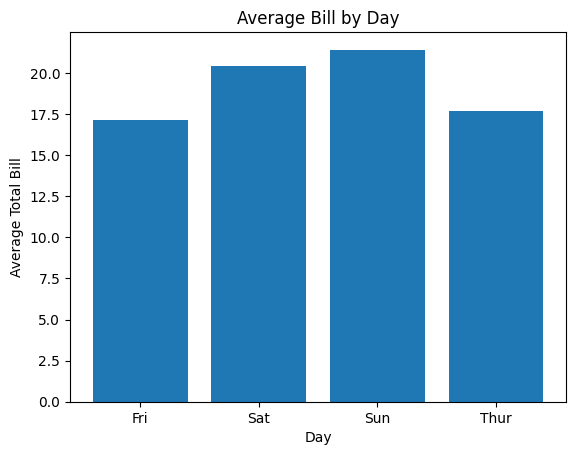

In [27]:
avg_by_day = tips.groupby('day')['total_bill'].mean()

plt.figure()
plt.bar(avg_by_day.index.astype(str), avg_by_day.values)
plt.title("Average Bill by Day")
plt.xlabel("Day")
plt.ylabel("Average Total Bill")
plt.show()


### Student Practice

Create a bar chart showing average `tip_pct` by `time` (Lunch vs Dinner). Give it a title and axis labels.


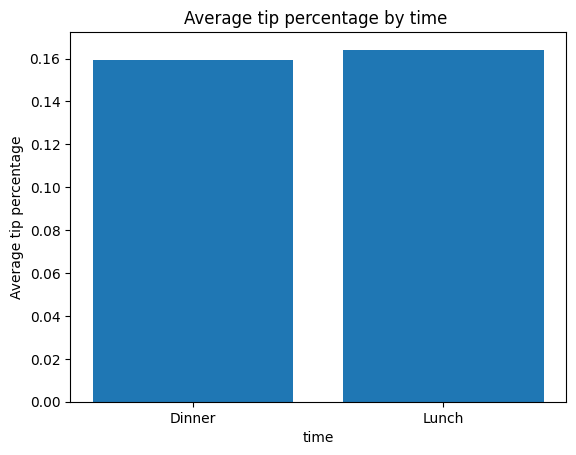

In [28]:
# Write your answer here

avg_tip = tips.groupby('time')['tip_pct'].mean()

plt.figure()
plt.bar(avg_tip.index.astype(str), avg_tip.values)
plt.title("Average tip percentage by time ")
plt.xlabel('time')
plt.ylabel('Average tip percentage')
plt.show()


## Part 10: Saving Your Work

### Demonstration


In [29]:
summary = tips.groupby('day').agg(
    avg_bill=('total_bill','mean'),
    avg_tip=('tip','mean')
).round(2)

summary.to_csv('day_summary.csv')
print("Saved day_summary.csv")
summary


Saved day_summary.csv


,avg_bill,avg_tip
day,,
Fri,17.15,2.73
Sat,20.44,2.99
Sun,21.41,3.26
Thur,17.68,2.77


### Student Practice

Save a CSV called `my_time_summary.csv` containing the average `total_bill` and `tip_pct` grouped by `time`.


In [30]:
# Write your answer here
my_time_summary = tips.groupby('time').agg(
    avg_bill = ('total_bill', 'mean'),
    avg_tip_pct = ('tip_pct', 'mean')

)
my_time_summary.to_csv('my_time_summary.csv')
print('successfully stored ')
my_time_summary


successfully stored 


,avg_bill,avg_tip_pct
time,,
Dinner,20.797,0.160
Lunch,17.169,0.164


**Reflection:** Why might you want to save intermediate results (like `summary`) to a CSV instead of just leaving them as a variable in the notebook?

*Your answer:*
so that we can use them later

# Mini Project A: Image Metadata Analysis (Image Track — continuing from NumPy lab)

Last week you analyzed a single image with NumPy (shape, brightness, RGB channels). Now you'll use pandas to compare **multiple images** at once — this is exactly how you'd organize a small image dataset for a computer vision project.

## Step 1: Build an image metadata table

For this project, upload **3-5 images** to Colab (reuse your NumPy lab technique), then build a DataFrame — one row per image — with columns: `filename`, `height`, `width`, `channels`, `avg_brightness`, `avg_red`, `avg_green`, `avg_blue`.

### Demonstration: the pattern for one image


In [31]:
from google.colab import files
uploaded = files.upload()


Saving 1387369.png to 1387369.png
Saving 4108274.jpg to 4108274.jpg
Saving 4108298.jpg to 4108298.jpg
Saving 4108305.jpg to 4108305.jpg


In [32]:
from PIL import Image
import numpy as np

filenames = list(uploaded.keys())
print("Uploaded files:", filenames)

# Demonstration: extract metadata for ONE image
sample_name = filenames[0]
img_array = np.array(Image.open(sample_name))

row = {
    'filename': sample_name,
    'height': img_array.shape[0],
    'width': img_array.shape[1],
    'channels': img_array.shape[2] if img_array.ndim == 3 else 1,
    'avg_brightness': np.mean(img_array),
    'avg_red': np.mean(img_array[:,:,0]) if img_array.ndim == 3 else np.mean(img_array),
    'avg_green': np.mean(img_array[:,:,1]) if img_array.ndim == 3 else np.mean(img_array),
    'avg_blue': np.mean(img_array[:,:,2]) if img_array.ndim == 3 else np.mean(img_array),
}
print(row)


Uploaded files: ['1387369.png', '4108274.jpg', '4108298.jpg', '4108305.jpg']
{'filename': '1387369.png', 'height': 1080, 'width': 1920, 'channels': 3, 'avg_brightness': np.float64(170.5613678305041), 'avg_red': np.float64(191.44628713348766), 'avg_green': np.float64(170.04519772376543), 'avg_blue': np.float64(150.19261863425925)}


### Student Practice

Loop over **all** uploaded `filenames` (not just the first one), build a `row` dictionary like above for each image, collect them into a list, and convert the list into a DataFrame using `pd.DataFrame(list_of_rows)`.


In [39]:
# Write your answer here
list_of_rows = []
for filename in filenames:
    img_array = np.array(Image.open(filename))
    row = {
        'filename': filename,
        'height': img_array.shape[0],
        'width': img_array.shape[1],
        'channels': img_array.shape[2] if img_array.ndim == 3 else 1
    }
    if img_array.ndim == 3:
        row['avg_brightness'] = np.mean(img_array)
        row['avg_red'] = np.mean(img_array[:,:,0])
        row['avg_green'] = np.mean(img_array[:,:,1])
        row['avg_blue'] = np.mean(img_array[:,:,2])
        list_of_rows.append(row)
    else:
        row['avg_brightness'] = np.mean(img_array)
        list_of_rows.append(row)
image_metadata = pd.DataFrame(list_of_rows)
image_metadata



,filename,height,width,channels,avg_brightness,avg_red,avg_green,avg_blue
0,1387369.png,1080,1920,3,170.561,191.446,170.045,150.193
1,4108274.jpg,2400,3840,3,99.551,84.813,109.490,104.351
2,4108298.jpg,784,1368,3,153.648,144.326,148.384,168.234
3,4108305.jpg,1800,2880,3,137.951,108.148,148.037,157.668


## Step 2: Analyze the image table with pandas

Once you have your image DataFrame, answer using pandas (not manual calculation):

1. Which image has the highest average brightness? (Hint: `.sort_values()` or `.idxmax()`)
2. What is the average brightness across all your images? (`.mean()`)
3. Create a bar chart comparing `avg_brightness` across all images (reuse Part 9's pattern).


**Reflection:** How is organizing multiple images into a DataFrame more useful than analyzing them one at a time like you did last week?

*Your answer:* yeah it good to analyze multiple images using pandas dataframe , i think it more efficient way for scale of images.


# Mini Project B: Word Frequency Table (NLP Track — continuing from NumPy lab)

Last week you built bag-of-words vectors and cosine similarity using raw NumPy. Now you'll organize word frequency data into a pandas DataFrame — the standard way this is done in real NLP pipelines.

## Step 1: Build a word frequency table

### Demonstration


In [35]:
sentence = "numpy makes numerical computing fast and numpy makes arrays powerful and pandas makes tables powerful"

tokens = sentence.lower().split()
tokens_array = np.array(tokens)
vocabulary = np.unique(tokens_array)

counts = [np.sum(tokens_array == word) for word in vocabulary]

word_freq = pd.DataFrame({'word': vocabulary, 'count': counts})
word_freq = word_freq.sort_values('count', ascending=False).reset_index(drop=True)
word_freq


,word,count
0,makes,3
1,and,2
2,powerful,2
3,numpy,2
4,arrays,1
5,computing,1
6,numerical,1
7,fast,1
8,pandas,1
9,tables,1


### Student Practice

1. Pick a paragraph of your own (3-4 sentences). Build a `word_freq` DataFrame for it using the same pattern.
2. Use pandas to find the top 5 most frequent words (`.head(5)`).
3. Use pandas to find how many words appear **only once** (Hint: filter where `count == 1`, then check `.shape[0]`).


In [44]:
# Write your answer here
paragraph = "numpy makes numerical computing fast and numpy makes arrays powerful and pandas makes tables powerful"
tokens = paragraph.lower().split()
tokens_array = np.array(tokens)
vocabulary = np.unique(tokens_array)

counts = [np.sum(tokens_array == word) for word in vocabulary]

word_freq = pd.DataFrame({'word': vocabulary, 'count': counts})
word_freq = word_freq.sort_values('count', ascending=False).reset_index(drop=True)
print(word_freq.head(5))
print(word_freq[word_freq['count'] == 1].shape[0])


       word  count
0     makes      3
1       and      2
2  powerful      2
3     numpy      2
4    arrays      1
6


## Step 2: Compare word frequency across multiple sentences

### Demonstration: build one table with per-sentence word counts


In [37]:
sentence_a = "machine learning uses numpy and pandas"
sentence_b = "deep learning also uses numpy and pandas heavily"

tokens_a = sentence_a.lower().split()
tokens_b = sentence_b.lower().split()
combined_vocab = np.unique(np.array(tokens_a + tokens_b))

table = pd.DataFrame({
    'word': combined_vocab,
    'sentence_a_count': [np.sum(np.array(tokens_a) == w) for w in combined_vocab],
    'sentence_b_count': [np.sum(np.array(tokens_b) == w) for w in combined_vocab],
})
table


,word,sentence_a_count,sentence_b_count
0,also,0,1
1,and,1,1
2,deep,0,1
3,heavily,0,1
4,learning,1,1
5,machine,1,0
6,numpy,1,1
7,pandas,1,1
8,uses,1,1


### Student Practice

Using the `table` above:
1. Add a new column `difference` = `sentence_a_count - sentence_b_count`.
2. Sort by `difference` to find which words are most unique to sentence A vs sentence B.
3. Which words appear in **both** sentences (count > 0 in both columns)? Filter and display them.


In [45]:
# Write your answer here
table['difference'] = table['sentence_a_count'] - table['sentence_b_count']
print(table.sort_values('difference'))
print(table[(table['sentence_a_count'] > 0) & (table['sentence_b_count'] > 0)])


       word  sentence_a_count  sentence_b_count  difference
0      also                 0                 1          -1
2      deep                 0                 1          -1
3   heavily                 0                 1          -1
1       and                 1                 1           0
4  learning                 1                 1           0
6     numpy                 1                 1           0
7    pandas                 1                 1           0
8      uses                 1                 1           0
5   machine                 1                 0           1
       word  sentence_a_count  sentence_b_count  difference
1       and                 1                 1           0
4  learning                 1                 1           0
6     numpy                 1                 1           0
7    pandas                 1                 1           0
8      uses                 1                 1           0


**Reflection:** Compare this pandas approach to building the same information with raw NumPy arrays last week. What does pandas make easier, and what (if anything) does it hide from you that NumPy made explicit?

*Your answer:*
pandas provides a powerful, user-friendly, and highly efficient layer over NumPy for data analysis, especially with structured, heterogeneous data. It sacrifices some of the low-level explicitness of NumPy for much greater convenience and readability in data manipulation tasks.

# Final Self-Check

- [ ] I loaded and inspected a real dataset using pandas
- [ ] I filtered, sorted, and created new columns myself
- [ ] I cleaned data (duplicates, missing values, dtypes, renaming) without just copying the demo
- [ ] I used `groupby()` to summarize data by category
- [ ] I merged two tables together
- [ ] I built at least one chart from a DataFrame
- [ ] I completed Mini Project A (image metadata) or B (word frequency), building the DataFrame myself
- [ ] I answered all reflection questions in my own words

## Final Reflection Questions

1. How is a pandas DataFrame related to a NumPy array? (Think back to last week's lab.)

A pandas DataFrame is built on top of NumPy arrays. It is like a 2D NumPy array but with row/column labels and extra features for handling and analyzing data.

2. Name one pandas operation that would be painful to do with raw NumPy arrays and loops instead, and explain why.

Grouping data using groupby() would be painful with raw NumPy arrays because we would need to manually find groups, loop through rows, and calculate results. Pandas can do this much more easily with a single operation.

3. Between the image metadata project and the word frequency project, which felt more like "real world data work" to you, and why?

The image metadata project felt more like real-world data work because image data can contain many different attributes such as file names, sizes, formats, dimensions, and dates. Cleaning and analyzing these different fields is similar to working with datasets in actual applications.

4. What's one pandas concept from this lab you still feel shaky on? Be specific — this helps guide review.

I still feel a little shaky on groupby(), especially understanding how to group data by multiple columns and then apply different aggregation functions like mean(), sum(), or count().
